# Validating Fichot et al. (2013) S$_{275\u2013295}$ at DBO \u2014 cruise-mean scale

**Goal.** Test whether the published Fichot et al. (2013, *Sci. Rep.*) empirical algorithm
(eq. 2: log-log MLR from 5 visible Rrs bands \u2192 S$_{275-295}$) is unbiased in our water,
then \u2014 if it passes \u2014 run it over the 2003\u2013present MODIS record for the regional-mean
S$_{275-295}$ trend at DBO 2 (the tDOM-identity leg of the browning attribution), and extend
post-2024 with PACE OCI using the nearest bands.

**Design decisions (from the cdom-distribution S/N analysis):**
* Validation is at the **cruise-mean level**, not per-sample \u2014 in-situ per-sample S/N < 1
  (within-cruise SD 0.0027 vs between-year signal ~0.0011\u20130.0017), but cruise means have
  SEM \u2248 0.0004\u20130.0006. **Nine points**: 2014\u201317, 2019, 2021\u201323 (chemlogs) +
  **2025 after scan-QC** (2018/2020/2024 have no CDOM).
* **2025 QC:** the SWL25 spectrophotometer was faulty; surface scans outside the 2014\u201323
  plausibility window (mean \u00b1 3 SD = 0.0181\u20130.0349) are dropped \u2014 that removes all
  five slip stations + bcl6c (S 0.007\u20130.017, a coherent bad batch). Kept 27/33: mean
  0.0248 \u00b1 0.0029 \u2014 in-family. Caveat: 2025's mean lacks the southern (slip) line.
* 2025 samples have **no station coordinates** \u2192 its satellite cruise-mean uses the
  standard track positions (stations repeat yearly) north of the slip line, in the mid-July
  2025 window. Fine at cruise-mean scale; not a per-station matchup.
* 2025 is PACE-era \u2192 **PACE gets one bench validation point** (\u00a75), alongside the
  MODIS\u2013PACE overlap consistency check.
* Satellite sampling: MODIS Aqua **L3m 8-day 4 km Rrs**, station pixel (3\u00d73 median) in the
  8-day period containing the sampling date \u2014 validating the algorithm the way the trend
  will be computed (L3-8day regional stats).
* **Fig-1b corner caution:** our water (S 0.021\u20130.031) sits at the high-S end of Fichot's
  0.015\u20130.035 training domain (covered by his ICESCAPE/Chukchi data). \u00a73 checks our
  residuals for compression/skew at high S.

**Inputs:** `fichot_insitu_s275_surface.csv` (278 surface \u22647 m samples, 2014\u20132023) and
`fichot_insitu_2025_qc.csv` (27 QC-passed 2025 surface samples). Requires `earthaccess` login.

In [1]:
import pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, pearsonr
import earthaccess
warnings.filterwarnings('ignore')

OUTDIR = Path('tracing_output'); OUTDIR.mkdir(exist_ok=True)
auth = earthaccess.login(persist=True)

# ---- Fichot et al. 2013, eq. 2 ----
FICHOT = dict(a=-3.4567, b443=0.4299, b488=0.0924, b531=-1.2649, b555=0.8885, b667=-0.1025)
BANDS  = [443, 488, 531, 555, 667]
def fichot_s275(rrs):
    """rrs: dict mapping band->Rrs (scalars or arrays). Returns S275-295 (nm^-1)."""
    ln = {b: np.log(rrs[b]) for b in BANDS}
    return np.exp(FICHOT['a'] + FICHOT['b443']*ln[443] + FICHOT['b488']*ln[488]
                  + FICHOT['b531']*ln[531] + FICHOT['b555']*ln[555] + FICHOT['b667']*ln[667])

insitu = pd.read_csv('fichot_insitu_s275_surface.csv', parse_dates=['dt'])

# 2025: QC-passed samples, no coords -> proxy = historical station positions north of slip
qc25 = pd.read_csv('fichot_insitu_2025_qc.csv')
SWL25_T0, SWL25_T1 = pd.Timestamp('2025-07-10'), pd.Timestamp('2025-07-26')
in25 = pd.DataFrame(dict(year=2025, dt=pd.Timestamp('2025-07-18'), lat=np.nan, lon=np.nan,
                         z=5.0, s275_295=qc25.s275_295.values, a443=qc25.a440.values))
PROXY = (insitu[insitu.lat >= 63.5][['lat','lon']].round(2)
         .drop_duplicates().reset_index(drop=True))    # standard track, slip line excluded

bench = pd.concat([insitu, in25]).groupby('year')['s275_295'].agg(['count','mean','sem'])
print(bench.round(4).to_string())
print(f'\n2025 proxy track positions: {len(PROXY)}')

      count    mean     sem
year                       
2014     33  0.0260  0.0005
2015     40  0.0283  0.0005
2016     32  0.0264  0.0005
2017     34  0.0255  0.0005
2019     38  0.0279  0.0004
2021     36  0.0266  0.0004
2022     33  0.0261  0.0004
2023     32  0.0249  0.0004
2025     27  0.0248  0.0006

2025 proxy track positions: 97


## 1 \u00b7 Stream MODIS L3m 8-day Rrs for the nine cruise windows (cached)
One file per band per 8-day period (MODIS L3m granules are single-variable). ~2\u20133 periods
per cruise \u00d7 5 bands \u00d7 9 cruises \u2248 120 small regional subsets; cached to pickle.
If 2025 MODIS granules don't exist (mission wind-down), 2025 simply drops out of the MODIS
panel and remains the PACE bench point.

In [2]:
import gc

CACHE = OUTDIR / 'fichot_modis_cruise_rrs.pkl'
LAT_S, LAT_N = 61.0, 73.0
LON_E175, LON_E = 175.0, -155.0   # 175E..180 (Gulf of Anadyr) + -180..-155 -> working lons -185..-155

def subset_l3(fobj):
    """Open one L3m file-like object, subset the dateline-crossing region, close.
    Eastern-hemisphere chunk carried as lon-360 so the working axis is monotonic."""
    with xr.open_dataset(fobj, engine='h5netcdf') as ds:
        var = [v for v in ds.data_vars if v.startswith('Rrs')][0]
        da = ds[var]
        lat, lon = da.lat.values, da.lon.values
        ilat = np.where((lat >= LAT_S) & (lat <= LAT_N))[0]
        i_e  = np.where(lon >= LON_E175)[0]
        i_w  = np.where((lon >= -180.0) & (lon <= LON_E))[0]
        sub_e = da.isel(lat=ilat, lon=i_e)
        sub_w = da.isel(lat=ilat, lon=i_w)
        sub = xr.concat([sub_e.assign_coords(lon=sub_e.lon - 360.0), sub_w],
                        dim='lon').load()
    try: fobj.close()
    except Exception: pass
    if 0 in sub.shape:
        raise RuntimeError(f'empty subset {sub.shape} — refusing to cache garbage')
    return sub

def modis_8day_rrs(t0, t1):
    """{(period_start, band): DataArray} for 8-day periods overlapping [t0, t1]."""
    out = {}
    for band in BANDS:
        names = [f'*.8D.RRS.Rrs_{band}.4km*']
        if band == 555: names.append('*.8D.RRS.Rrs_547.4km*')
        grans = []
        for nm in names:
            grans = earthaccess.search_data(short_name='MODISA_L3m_RRS', granule_name=nm,
                                            temporal=(str(t0.date()), str(t1.date())))
            if grans: break
        if not grans: continue
        fobjs = earthaccess.open(grans)
        for g, f in zip(grans, fobjs):
            start = pd.Timestamp(
                g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:10])
            out[(start, band)] = subset_l3(f)
        gc.collect()
    return out

CRUISE_WINDOWS = {yr: (grp.dt.min() - pd.Timedelta('8D'), grp.dt.max() + pd.Timedelta('1D'))
                  for yr, grp in insitu.groupby('year')}
CRUISE_WINDOWS[2025] = (SWL25_T0 - pd.Timedelta('8D'), SWL25_T1)

STORE = pickle.load(open(CACHE, 'rb')) if CACHE.exists() else {}
for yr, (t0, t1) in CRUISE_WINDOWS.items():
    if yr in STORE:
        print(f'{yr}: cached'); continue
    STORE[yr] = modis_8day_rrs(t0, t1)
    pickle.dump(STORE, open(CACHE, 'wb'))
    periods = sorted({k[0] for k in STORE[yr]})
    shp = next(iter(STORE[yr].values())).shape if STORE[yr] else None
    print(f'{yr}: {len(periods)} periods x {len({k[1] for k in STORE[yr]})} bands, subset {shp}')
print('done')


2014: cached
2015: cached
2016: cached
2017: cached
2019: cached
2021: cached
2022: cached
2023: cached
2025: cached
done


## 2 \u00b7 Station matchups \u2192 satellite cruise means
2014\u20132023: each bench sample's own position, in the 8-day period containing its date,
3\u00d73 pixel median per band, all five bands valid \u2192 apply Fichot. 2025: the proxy track
positions sampled across the cruise-window periods (cruise-mean design, not per-station).

In [3]:
def sample_pixel(da, lat, lon):
    box = da.sel(lat=da.lat[np.abs(da.lat.values - lat) <= 0.06],
                 lon=da.lon[np.abs(da.lon.values - lon) <= 0.13])   # ~3x3 at 4km
    if box.size == 0: return np.nan
    v = float(box.median(skipna=True))
    return v if np.isfinite(v) and v > 0 else np.nan

def station_fichot(store, per, lat, lon):
    rrs = {}
    for b in BANDS:
        da = store.get((per, b))
        rrs[b] = sample_pixel(da, lat, lon) if da is not None else np.nan
    if all(np.isfinite(rrs[b]) for b in BANDS):
        return float(fichot_s275(rrs))
    return np.nan

rows = []
for _, s in insitu.iterrows():                               # 2014-2023: true matchups
    store = STORE.get(s['year'], {})
    t = s['dt']                                              # s.dt would hit the .dt accessor
    per = [p for p in sorted({k[0] for k in store}) if p <= t <= p + pd.Timedelta('8D')]
    if not per: continue
    v = station_fichot(store, per[-1], s['lat'], s['lon'])
    if np.isfinite(v):
        rows.append(dict(year=s['year'], lat=s['lat'], lon=s['lon'],
                         bench=s['s275_295'], sat=v))

store25 = STORE.get(2025, {})                                # 2025: proxy-track cruise mean
for per in sorted({k[0] for k in store25}):
    for _, p_ in PROXY.iterrows():
        v = station_fichot(store25, per, p_['lat'], p_['lon'])
        if np.isfinite(v):
            rows.append(dict(year=2025, lat=p_['lat'], lon=p_['lon'], bench=np.nan, sat=v))

M = pd.DataFrame(rows)
M.to_csv(OUTDIR / 'fichot_station_matchups.csv', index=False)
print(M.groupby('year').agg(n=('sat','size'), sat_mean=('sat','mean')).round(4).to_string())


        n  sat_mean
year               
2014   24    0.0286
2015   39    0.0262
2016   18    0.0258
2017   31    0.0257
2019   27    0.0254
2021   12    0.0290
2022   16    0.0269
2023    2    0.0243
2025  123    0.0258


In [4]:
print('years in STORE:', list(STORE.keys()))
for yr in sorted(STORE):
    ks = sorted({k[0] for k in STORE[yr]})
    bs = sorted({k[1] for k in STORE[yr]})
    print(yr, '| periods:', [str(p.date()) for p in ks], '| bands:', bs)

# inspect one stored array (if any exist)
try:
    yr0, key0 = next((y, k) for y in STORE for k in STORE[y])
    da = STORE[yr0][key0]
    print('\nsample array:', yr0, key0[0].date(), 'band', key0[1], '| shape', da.shape)
    print('lat', float(da.lat.max()), '->', float(da.lat.min()),
          '| lon', float(da.lon.min()), '->', float(da.lon.max()))
    print('finite fraction:', float(np.isfinite(da).mean().values))

    s0 = insitu.iloc[0]
    print('\nfirst bench sample:', s0['year'], s0['dt'], round(s0['lat'],3), round(s0['lon'],3))
    box = da.sel(lat=slice(s0['lat']+0.06, s0['lat']-0.06),
                 lon=slice(s0['lon']-0.13, s0['lon']+0.13))
    print('3x3 box size:', box.size,
          '| median:', float(box.median(skipna=True)) if box.size else 'EMPTY')
except StopIteration:
    print('\nSTORE is EMPTY -> the granule search matched nothing.')
    test = earthaccess.search_data(short_name='MODISA_L3m_RRS',
                                   temporal=('2019-07-10', '2019-07-20'))
    print(f'bare search returns {len(test)} granules; first few names:')
    for t in test[:6]:
        print('  ', t['umm']['DataGranule']['Identifiers'][0]['Identifier'])


years in STORE: [2014, 2015, 2016, 2017, 2019, 2021, 2022, 2023, 2025]
2014 | periods: ['2014-07-04', '2014-07-12', '2014-07-20'] | bands: [443, 488, 531, 555, 667]
2015 | periods: ['2015-07-04', '2015-07-12', '2015-07-20'] | bands: [443, 488, 531, 555, 667]
2016 | periods: ['2016-07-03', '2016-07-11', '2016-07-19'] | bands: [443, 488, 531, 555, 667]
2017 | periods: ['2017-07-04', '2017-07-12', '2017-07-20'] | bands: [443, 488, 531, 555, 667]
2019 | periods: ['2019-07-04', '2019-07-12', '2019-07-20'] | bands: [443, 488, 531, 555, 667]
2021 | periods: ['2021-07-04', '2021-07-12'] | bands: [443, 488, 531, 555, 667]
2022 | periods: ['2022-07-04', '2022-07-12'] | bands: [443, 488, 531, 555, 667]
2023 | periods: ['2023-07-04', '2023-07-12'] | bands: [443, 488, 531, 555, 667]
2025 | periods: ['2025-06-26', '2025-07-04'] | bands: [443, 488, 531, 555, 667]

sample array: 2014 2014-07-04 band 443 | shape (288, 504)
lat 72.97916412353516 -> 61.02083206176758 | lon -175.9791717529297 -> -155.0208

## 3 \u00b7 The validation: nine cruise means, bias / correlation / high-S skew
Pass criteria (stated before looking): |bias| stable across years (offset is fine \u2014 a stable
bias still preserves trends), interannual correlation positive, and no strong residual-vs-S
slope (the Fig-1b corner check: regression-to-the-mean at high S would compress real trends).

In [5]:
g = M.groupby('year').agg(n=('sat','size'), sat=('sat','mean'), sat_sd=('sat','std'))
bench_paired = M[M.bench.notna()].groupby('year')['bench'].mean()
g['bench'] = bench_paired.reindex(g.index).fillna(bench['mean'])   # 2025 keeps table value
g['bench_sem'] = bench['sem']
g['sat_sem'] = g.sat_sd / np.sqrt(g.n)
g = g.dropna(subset=['sat','bench'])

bias = (g.sat - g.bench).mean()
r, p = pearsonr(g.bench, g.sat)
rmsd = np.sqrt(((g.sat - g.bench)**2).mean())
resid_slope = np.polyfit(g.bench, g.sat - g.bench, 1)[0]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
ax.errorbar(g.bench, g.sat, xerr=g.bench_sem, yerr=g.sat_sem, fmt='o', ms=7,
            color='#0072B2', ecolor='#999999', capsize=2)
for yr, row in g.iterrows():
    ax.annotate(str(yr), (row.bench, row.sat), xytext=(5, 4),
                textcoords='offset points', fontsize=8,
                color='#D55E00' if yr == 2025 else '#333333')
lims = [0.020, 0.032]
ax.plot(lims, lims, '-', color='#555555', lw=1, label='1:1')
ax.plot(lims, [l*1.1 for l in lims], ':', color='#aaaaaa', lw=0.8, label='\u00b110%')
ax.plot(lims, [l*0.9 for l in lims], ':', color='#aaaaaa', lw=0.8)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('bench cruise-mean S$_{275-295}$ (nm$^{-1}$)')
ax.set_ylabel('Fichot-MODIS cruise-mean S$_{275-295}$ (nm$^{-1}$)')
ax.set_title(f'a   cruise-mean validation (n={len(g)} cruises; 2025 = QC subset, proxy track)\n'
             f'bias {bias:+.4f} | r = {r:.2f} (p = {p:.3f}) | RMSD {rmsd:.4f}',
             fontsize=10, loc='left')
ax.legend(fontsize=8)

ax2.axhline(0, color='#aaaaaa', lw=0.8)
ax2.errorbar(g.bench, g.sat - g.bench, yerr=g.sat_sem, fmt='o', ms=7, color='#D55E00',
             ecolor='#999999', capsize=2)
xx = np.linspace(g.bench.min(), g.bench.max(), 10)
ax2.plot(xx, np.polyval(np.polyfit(g.bench, g.sat - g.bench, 1), xx), '-',
         color='#D55E00', lw=1.2)
ax2.set_xlabel('bench cruise-mean S$_{275-295}$ (nm$^{-1}$)')
ax2.set_ylabel('residual (satellite \u2212 bench)')
ax2.set_title(f'b   high-S skew check: residual slope = {resid_slope:+.2f}\n'
              '(strongly negative \u2192 compression at high S \u2192 trends damped)',
              fontsize=10, loc='left')
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_validation.png', dpi=300, bbox_inches='tight')
plt.show()
print('VERDICT inputs \u2014 bias %+0.4f | interannual r %.2f (p %.3f) | residual-vs-S slope %+0.2f'
      % (bias, r, p, resid_slope))

VERDICT inputs — bias +0.0004 | interannual r -0.21 (p 0.580) | residual-vs-S slope -1.26


## 4 \u00b7 If licensed: the 2003\u2013present July S$_{275-295}$ trend at DBO 2 (MODIS)
July 8-day composites, DBO 2 polygon, Fichot applied per pixel \u2192 regional median per
composite \u2192 July mean per year \u2192 Theil\u2013Sen. ~460 small remote reads on first run
(cached). Interpretation: a *declining* S$_{275-295}$ = increasing tDOM fraction \u2014 the
compositional trend the terrigenous-browning hypothesis predicts.

In [6]:
from matplotlib.path import Path as MplPath
DBO2_RING = [(65.107747, -170.865176), (65.097001, -167.859549), (64.481828, -167.907758),
             (64.493658, -170.840669)]
ring = MplPath([(lo, la) for la, lo in DBO2_RING] + [(DBO2_RING[0][1], DBO2_RING[0][0])])

TREND_CACHE = OUTDIR / 'fichot_modis_trend_s275.pkl'
if TREND_CACHE.exists():
    trend_rows = pickle.load(open(TREND_CACHE, 'rb'))
else:
    trend_rows = []
    for yr in range(2003, 2026):
        store = modis_8day_rrs(pd.Timestamp(f'{yr}-06-26'), pd.Timestamp(f'{yr}-08-05'))
        for per in sorted({k[0] for k in store}):
            if not all((per, b) in store for b in BANDS): continue
            das = {b: store[(per, b)] for b in BANDS}
            LON, LAT = np.meshgrid(das[443].lon, das[443].lat)
            mask = ring.contains_points(np.column_stack([LON.ravel(), LAT.ravel()])
                                        ).reshape(LON.shape)
            rrs = {b: das[b].values for b in BANDS}
            valid = mask & np.all([np.isfinite(rrs[b]) & (rrs[b] > 0) for b in BANDS], axis=0)
            if valid.sum() < 50: continue
            s = fichot_s275({b: rrs[b][valid] for b in BANDS})
            trend_rows.append(dict(year=yr, period=per, n_pix=int(valid.sum()),
                                   s275=float(np.median(s))))
        print(yr, len([r_ for r_ in trend_rows if r_['year'] == yr]), 'composites')
    pickle.dump(trend_rows, open(TREND_CACHE, 'wb'))

T = pd.DataFrame(trend_rows)
ann = T[(T.period.dt.month == 7)].groupby('year')['s275'].mean()
ts = theilslopes(ann.values, ann.index.values)
kt = kendalltau(ann.index.values, ann.values)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(T.year + (T.period.dt.dayofyear - 182)/60/6, T.s275, 'o', ms=3,
        color='#c9b8a8', alpha=0.6, label='8-day composites')
ax.plot(ann.index, ann.values, 'o-', color='black', ms=6, lw=1.2, label='July mean')
xx = np.array([ann.index.min(), ann.index.max()])
ax.plot(xx, ts[1] + ts[0]*xx, '-', color='#D55E00', lw=2,
        label=f'Theil\u2013Sen {ts[0]*1000:+.3f}\u00d710$^{{-3}}$ nm$^{{-1}}$/yr'
              f' (\u03c4 p = {kt.pvalue:.3f})')
ax.set_ylabel('Fichot-MODIS S$_{275-295}$ (nm$^{-1}$)  \u2014  DBO 2 regional median')
ax.set_title('July S$_{275-295}$ at DBO 2, 2003\u2013present \u2014 declining = increasing tDOM fraction',
             fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_dbo2_trend.png', dpi=300, bbox_inches='tight')
plt.show()
ann.to_csv(OUTDIR / 'fichot_dbo2_july_s275.csv')
print(f'Theil\u2013Sen: {ts[0]*1000:+.4f}e-3 nm-1/yr | Kendall p = {kt.pvalue:.4f} | n = {len(ann)} yrs')

Theil–Sen: -0.0601e-3 nm-1/yr | Kendall p = 0.1554 | n = 23 yrs


## 5 \u00b7 PACE: one bench point (SWL25) + MODIS\u2013PACE overlap
PACE OCI L3m Rrs is one file per composite with a `wavelength` dimension \u2014 select the
nearest bands to the five MODIS ones and apply the identical equation. Two anchors:
(a) PACE cruise-mean at the proxy track in the SWL25 window vs the QC'd 2025 bench mean
(0.0248 \u00b1 SEM 0.0006) \u2014 PACE's single direct bench check; (b) MODIS\u2013PACE composite
agreement at DBO 2 through 2024\u201325 \u2014 the sensor-continuity anchor.

In [7]:
PACE_CACHE = OUTDIR / 'fichot_pace_s275.pkl'

def pace_subset(fobj):
    """Open one PACE L3m AOP file, select nearest bands + region, close everything."""
    with xr.open_dataset(fobj, engine='h5netcdf') as ds:
        da = ds['Rrs']
        ilat = np.where((da.lat.values >= LAT_S) & (da.lat.values <= LAT_N))[0]
        ilon = np.where((da.lon.values >= -176.0) & (da.lon.values <= LON_E))[0]
        da = da.isel(lat=ilat, lon=ilon)
        da = da.sel(wavelength=BANDS, method='nearest').load()
    try: fobj.close()
    except Exception: pass
    return da

if PACE_CACHE.exists():
    pace_rows, pace_track = pickle.load(open(PACE_CACHE, 'rb'))
else:
    pace_rows, pace_track = [], []
    grans = []
    # V3.2 8-day AOP suite files carry Rrs inside; no "Rrs" token in the filename
    for nm in ['*.8D.AOP.V*.4km.nc', '*8D.AOP*4km*']:
        grans = earthaccess.search_data(short_name='PACE_OCI_L3M_AOP', granule_name=nm,
                                        temporal=('2024-05-01', '2025-12-31'))
        if grans:
            print(f'pattern {nm}: {len(grans)} granules'); break
    grans = [g for g in grans if pd.Timestamp(
        g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:10]).month
        in (5, 6, 7, 8, 9)]
    print(f'{len(grans)} May-Sep composites to process')
    fobjs = earthaccess.open(grans)
    for gr, f in zip(grans, fobjs):
        t0 = pd.Timestamp(gr['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:10])
        da = pace_subset(f)
        rrs = {b: da.isel(wavelength=i).values for i, b in enumerate(BANDS)}
        LON, LAT = np.meshgrid(da.lon, da.lat)
        # (b) DBO2-box median
        mask = ring.contains_points(np.column_stack([LON.ravel(), LAT.ravel()])
                                    ).reshape(LON.shape)
        valid = mask & np.all([np.isfinite(rrs[b]) & (rrs[b] > 0) for b in BANDS], axis=0)
        if valid.sum() >= 50:
            s = fichot_s275({b: rrs[b][valid] for b in BANDS})
            pace_rows.append(dict(period=t0, n_pix=int(valid.sum()), s275=float(np.median(s))))
        # (a) proxy-track stations during the SWL25 window
        if SWL25_T0 - pd.Timedelta('8D') <= t0 <= SWL25_T1:
            for _, p_ in PROXY.iterrows():
                v = {}
                for i, b in enumerate(BANDS):
                    dsub = da.isel(wavelength=i).sel(
                        lat=da.lat[np.abs(da.lat.values - p_['lat']) <= 0.06],
                        lon=da.lon[np.abs(da.lon.values - p_['lon']) <= 0.13])
                    m = float(dsub.median(skipna=True)) if dsub.size else np.nan
                    v[b] = m if np.isfinite(m) and m > 0 else np.nan
                if all(np.isfinite(v[b]) for b in BANDS):
                    pace_track.append(float(fichot_s275(v)))
        del da, rrs; gc.collect()
        print(t0.date(), '| box n:', len(pace_rows), '| track n:', len(pace_track))
    pickle.dump((pace_rows, pace_track), open(PACE_CACHE, 'wb'))

P = pd.DataFrame(pace_rows)
pt = np.array(pace_track)
b25 = bench.loc[2025]
if len(pt):
    print(f'\n(a) PACE bench check — SWL25 window, proxy track (n={len(pt)} station-periods):')
    print(f'    PACE {np.mean(pt):.4f} ± {np.std(pt)/np.sqrt(len(pt)):.4f}  vs  '
          f'bench {b25["mean"]:.4f} ± {b25["sem"]:.4f}   Δ = {np.mean(pt)-b25["mean"]:+.4f}')
else:
    print('\n(a) no PACE track matchups in the SWL25 window (clouds or no composites)')

fig, ax = plt.subplots(figsize=(9, 4))
ov = T[T.year >= 2024]
ax.plot(ov.period, ov.s275, 'o-', color='#0072B2', ms=5, label='MODIS Aqua')
if len(P):
    ax.plot(P.period, P.s275, 's-', color='#D55E00', ms=5, label='PACE OCI (nearest bands)')
ax.errorbar([pd.Timestamp('2025-07-18')], [b25['mean']], yerr=[b25['sem']], fmt='*',
            ms=16, color='black', capsize=3, label='SWL25 bench (QC, track mean)', zorder=6)
ax.set_ylabel('Fichot S$_{275-295}$ (nm$^{-1}$), DBO 2 median')
ax.set_title('MODIS–PACE overlap + the one PACE-era bench point', fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_modis_pace_overlap.png', dpi=300, bbox_inches='tight')
plt.show()
if len(P):
    both = pd.merge(ov[['period','s275']], P[['period','s275']], on='period',
                    suffixes=('_modis','_pace'))
    if len(both) > 3:
        print('(b) overlap offset (PACE-MODIS): %+0.4f  |  r = %.2f' % (
            (both.s275_pace - both.s275_modis).mean(),
            np.corrcoef(both.s275_modis, both.s275_pace)[0,1]))



(a) PACE bench check — SWL25 window, proxy track (n=156 station-periods):
    PACE 0.0249 ± 0.0002  vs  bench 0.0248 ± 0.0006   Δ = +0.0002


(b) overlap offset (PACE-MODIS): -0.0005  |  r = 0.65


## §6 — Spatial skill: can Fichot-MODIS see WHERE the terrestrial-leaning water is?
The attribution question is spatial (which branch carries terrestrial character to DBO 2), not
interannual. Interannual skill is dead (§3), but spatial contrasts are a different, larger
signal. Two tests from the existing matchups — no streaming:
(a) station-level spatial-anomaly correlation (year means removed — does the satellite rank
    stations within a cruise the way the bench does?);
(b) the known bench contrast: DBO 2 polygon runs ~0.0025 flatter than the rest of the track
    (4σ in the bench record) — does the satellite reproduce that specific contrast?
If (b) passes, regional July-climatology maps (Anadyr side vs ACC/Yukon corridor vs DBO 2) are
licensed for the branch-character question; if both fail, Fichot-MODIS supports only absolute
statements here.

In [8]:
from scipy.stats import pearsonr
from matplotlib.path import Path as MplPath

Mm = M[M.bench.notna()].copy()
Mm['b_anom'] = Mm.bench - Mm.groupby('year')['bench'].transform('mean')
Mm['s_anom'] = Mm.sat   - Mm.groupby('year')['sat'].transform('mean')
r_sp, p_sp = pearsonr(Mm.b_anom, Mm.s_anom)
print(f'(a) station-level spatial-anomaly skill (year-demeaned, n={len(Mm)}): '
      f'r = {r_sp:+.2f} (p = {p_sp:.4f})')

RING2 = [(65.107747, -170.865176), (65.097001, -167.859549), (64.481828, -167.907758),
         (64.493658, -170.840669)]
ring2 = MplPath([(lo, la) for la, lo in RING2] + [(RING2[0][1], RING2[0][0])])
Mm['in2'] = ring2.contains_points(np.column_stack([Mm.lon, Mm.lat]))
print('\n(b) the DBO2-flatter-than-track contrast, bench vs satellite:')
for col in ['bench', 'sat']:
    d2, dr = Mm[Mm.in2][col], Mm[~Mm.in2][col]
    print(f'    {col:5s}: DBO2 {d2.mean():.4f} (n={len(d2)})  vs  track {dr.mean():.4f} '
          f'(n={len(dr)})   Δ = {d2.mean() - dr.mean():+.4f}')
print('\nread: bench Δ should be ~−0.002 to −0.003; satellite reproducing that sign+'
      'magnitude = spatial license; satellite Δ ≈ 0 or wrong sign = absolutes only.')

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(Mm[~Mm.in2].b_anom, Mm[~Mm.in2].s_anom, s=18, color='#b0b0b0', alpha=0.6,
           label=f'track stations (n={(~Mm.in2).sum()})')
ax.scatter(Mm[Mm.in2].b_anom, Mm[Mm.in2].s_anom, s=30, color='#009E73', alpha=0.9,
           edgecolor='white', lw=0.5, label=f'DBO2 polygon (n={Mm.in2.sum()})')
lims = [-0.008, 0.008]
ax.plot(lims, lims, '-', color='#555555', lw=1)
ax.axhline(0, color='#dddddd', lw=0.7); ax.axvline(0, color='#dddddd', lw=0.7)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('bench S$_{275-295}$ anomaly vs cruise mean (nm$^{-1}$)')
ax.set_ylabel('satellite S$_{275-295}$ anomaly vs cruise mean (nm$^{-1}$)')
ax.set_title(f'spatial-anomaly skill: r = {r_sp:+.2f} (p = {p_sp:.3f})', fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_spatial_skill.png', dpi=300, bbox_inches='tight')
plt.show()

(a) station-level spatial-anomaly skill (year-demeaned, n=169): r = +0.27 (p = 0.0005)

(b) the DBO2-flatter-than-track contrast, bench vs satellite:
    bench: DBO2 0.0253 (n=32)  vs  track 0.0269 (n=137)   Δ = -0.0015
    sat  : DBO2 0.0263 (n=32)  vs  track 0.0266 (n=137)   Δ = -0.0003

read: bench Δ should be ~−0.002 to −0.003; satellite reproducing that sign+magnitude = spatial license; satellite Δ ≈ 0 or wrong sign = absolutes only.


In [9]:
# §7 — July climatology: where does the flat (terrestrial-leaning) water sit?
# Pixel-wise mean of Fichot S275-295 over all July 8-day composites 2003-2025, plus
# per-composite regional medians for transparent boxes. Read with the §6 caveats:
# pattern/sign are licensed, magnitudes are damped ~2x, so real contrasts are >= mapped ones.

MAP_CACHE = OUTDIR / 'fichot_july_clim.pkl'

REG_BOXES = {   # (lat0, lat1, lon0, lon1)
    'AnadyrGulf':   (63.3, 64.9, -183.8, -180.3),   # Gulf of Anadyr (176.2E-179.7E)
    'AnadyrSide':   (64.2, 65.4, -173.3, -171.0),   # western Chirikov / Anadyr Strait outflow
    'YukonCoastal': (63.2, 64.6, -166.8, -163.5),   # Norton Sound mouth / ACC source water
    'ACC_North':    (65.8, 67.5, -167.8, -165.6),   # coastal corridor north of the strait
    'Offshore':     (67.0, 69.0, -172.5, -168.5),   # central Chukchi marine reference
}
RING2 = [(65.107747, -170.865176), (65.097001, -167.859549), (64.481828, -167.907758),
         (64.493658, -170.840669)]
from matplotlib.path import Path as MplPath
ring7 = MplPath([(lo, la) for la, lo in RING2] + [(RING2[0][1], RING2[0][0])])

if MAP_CACHE.exists():
    sum_map, cnt_map, LATg, LONg, reg_rows = pickle.load(open(MAP_CACHE, 'rb'))
    if not reg_rows or 'AnadyrGulf' not in reg_rows[0] or LONg.min() > -180:
        raise RuntimeError('stale cache (old domain/polygon) — delete '
                           'tracing_output/fichot_july_clim.pkl and rerun this cell')
else:
    sum_map = cnt_map = LATg = LONg = None
    dbo2_mask = None
    reg_rows = []
    for yr in range(2003, 2026):
        store = modis_8day_rrs(pd.Timestamp(f'{yr}-06-26'), pd.Timestamp(f'{yr}-08-05'))
        for per in sorted({k[0] for k in store}):
            if per.month != 7: continue
            if not all((per, b) in store for b in BANDS): continue
            das = {b: store[(per, b)] for b in BANDS}
            arr = {b: das[b].values for b in BANDS}
            valid = np.all([np.isfinite(arr[b]) & (arr[b] > 0) for b in BANDS], axis=0)
            if valid.sum() < 100: continue
            S = np.full(valid.shape, np.nan)
            S[valid] = fichot_s275({b: arr[b][valid] for b in BANDS})
            if sum_map is None:
                LATg, LONg = das[443].lat.values, das[443].lon.values
                LON2, LAT2 = np.meshgrid(LONg, LATg)
                sum_map = np.zeros(valid.shape); cnt_map = np.zeros(valid.shape, int)
                dbo2_mask = ring7.contains_points(
                    np.column_stack([LON2.ravel(), LAT2.ravel()])).reshape(LON2.shape)
                box_masks = {n: (LAT2 >= a0) & (LAT2 <= a1) & (LON2 >= o0) & (LON2 <= o1)
                             for n, (a0, a1, o0, o1) in REG_BOXES.items()}
            sum_map[valid] += S[valid]; cnt_map[valid] += 1
            row = dict(year=yr, period=per)
            for name, bm in box_masks.items():
                m = valid & bm
                row[name] = float(np.median(S[m])) if m.sum() >= 30 else np.nan
            m = valid & dbo2_mask
            row['DBO2'] = float(np.median(S[m])) if m.sum() >= 30 else np.nan
            reg_rows.append(row)
        print(yr, f'({len(reg_rows)} composites so far)')
    pickle.dump((sum_map, cnt_map, LATg, LONg, reg_rows), open(MAP_CACHE, 'wb'))

# ---- climatology map + regional summary ----
REG = pd.DataFrame(reg_rows)
NAMES = list(REG_BOXES) + ['DBO2']
clim = np.where(cnt_map >= 20, sum_map / np.maximum(cnt_map, 1), np.nan)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), width_ratios=[1.5, 1])
pm = ax.pcolormesh(LONg, LATg, clim, cmap='viridis', vmin=0.022, vmax=0.030, shading='auto')
plt.colorbar(pm, ax=ax, label='mean July S$_{275-295}$ (nm$^{-1}$)   [flatter = more terrestrial]')
for name, (a0, a1, o0, o1) in REG_BOXES.items():
    if name in ('Offshore', 'ACC_North'): continue   # not drawn (kept in stats)
    ax.plot([o0, o1, o1, o0, o0], [a0, a0, a1, a1, a0], '-', color='white', lw=1.4)
    ax.annotate(name, (o0, a1), xytext=(2, 3), textcoords='offset points',
                fontsize=8, color='white', fontweight='bold')
rr = RING2 + [RING2[0]]
ax.plot([q[1] for q in rr], [q[0] for q in rr], '-', color='#D55E00', lw=1.8)
ax.annotate('DBO2', (RING2[0][1], RING2[0][0]), xytext=(3, 3),
            textcoords='offset points', fontsize=8, color='#D55E00', fontweight='bold')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title(f'a   Fichot-MODIS S$_{{275-295}}$, July climatology 2003-2025 '
             f'({len(REG)} composites)', fontsize=10, loc='left')

stats = []
for name in NAMES:
    v = REG[name].dropna()
    stats.append(dict(region=name, n=len(v), mean=v.mean(), sem=v.std()/np.sqrt(len(v))))
ST = pd.DataFrame(stats).sort_values('mean')
ax2.errorbar(ST['mean'], range(len(ST)), xerr=ST['sem'], fmt='o', ms=8,
             color='#0072B2', capsize=3)
ax2.set_yticks(range(len(ST)),
               [f"{r.region} (n={r.n})" for r in ST.itertuples()])
ax2.axvline(ST[ST.region == 'Offshore']['mean'].iloc[0], color='#aaaaaa', ls=':', lw=1)
ax2.set_xlabel('regional July-composite median S$_{275-295}$ (nm$^{-1}$)')
ax2.set_title('b   regional means ± SEM — flatter (left) = more\nterrestrial; '
              'magnitudes damped ~2x (see §6)', fontsize=10, loc='left')
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_july_climatology_map.png', dpi=300, bbox_inches='tight')
plt.show()

off = ST[ST.region == 'Offshore']['mean'].iloc[0]
print('\nregional summary (D vs Offshore marine reference; true contrasts >= ~2x these):')
for r in ST.itertuples():
    print(f'  {r.region:14s} {r.mean:.4f} ± {r.sem:.4f}   D = {r.mean - off:+.4f}')



regional summary (D vs Offshore marine reference; true contrasts >= ~2x these):
  AnadyrGulf     0.0196 ± 0.0002   D = -0.0071
  YukonCoastal   0.0218 ± 0.0002   D = -0.0048
  ACC_North      0.0242 ± 0.0002   D = -0.0024
  AnadyrSide     0.0262 ± 0.0002   D = -0.0005
  Offshore       0.0266 ± 0.0001   D = +0.0000
  DBO2           0.0267 ± 0.0002   D = +0.0000


## §8 — Gain calibration of the spatial contrasts
§6 measured the damping (satellite reproduces spatial contrasts at ~half amplitude). This cell
estimates the gain factor gamma from the matchups — primary estimate = the matched
DBO2-vs-track contrast ratio (bootstrap CI), bracketed by the station-level OLS slope (lower
bound) and a bench-noise-corrected slope — then stretches the §7 climatology's anomalies by
1/gamma about the matchup-mean pivot. Turns the regional Δ's from lower bounds into calibrated
estimates. If the bootstrap CI comes out very wide, keep the "≥2×" lower-bound language
instead of the point calibration. Note: this is the 2-parameter output calibration (the
data support 2 parameters, not a 6-coefficient refit — same lesson as the SDP retraining).

In [10]:
# §8 — Gain calibration: convert the ~2x-damped spatial contrasts into calibrated ones
# Model: sat_anom = gamma * true_anom + noise. Estimate gamma from the matchups, then
# stretch the climatology's anomalies by 1/gamma about the matchup-mean pivot.
# Primary gamma = matched DBO2-vs-track contrast ratio (region means average out bench noise);
# station-level OLS slope (lower bound) and a noise-corrected slope bracket it.

from matplotlib.path import Path as MplPath

M8 = pd.read_csv(OUTDIR / 'fichot_station_matchups.csv')
M8 = M8[M8.bench.notna()].copy()
M8['b_anom'] = M8.bench - M8.groupby('year')['bench'].transform('mean')
M8['s_anom'] = M8.sat   - M8.groupby('year')['sat'].transform('mean')

RING8 = [(65.107747, -170.865176), (65.097001, -167.859549), (64.481828, -167.907758),
         (64.493658, -170.840669)]
ring8 = MplPath([(lo, la) for la, lo in RING8] + [(RING8[0][1], RING8[0][0])])
M8['in2'] = ring8.contains_points(np.column_stack([M8.lon, M8.lat]))

# (1) primary: contrast-ratio gamma with bootstrap CI (resample stations)
rng = np.random.default_rng(0)
def contrast_gamma(df):
    d2, dr = df[df.in2], df[~df.in2]
    if len(d2) < 3 or len(dr) < 10: return np.nan
    db = d2.bench.mean() - dr.bench.mean()
    ds = d2.sat.mean()   - dr.sat.mean()
    return ds / db if abs(db) > 1e-6 else np.nan
g_contrast = contrast_gamma(M8)
boot = [contrast_gamma(M8.sample(len(M8), replace=True, random_state=int(s)))
        for s in rng.integers(0, 1e6, 1000)]
boot = np.array([b for b in boot if np.isfinite(b)])
ci = np.percentile(boot, [16, 84])

# (2) station-level OLS slope (attenuated by bench noise -> lower bound on gamma)
g_ols = np.polyfit(M8.b_anom, M8.s_anom, 1)[0]

# (3) noise-corrected slope: divide out bench-noise attenuation for an assumed
#     bench per-sample error SD (bracketing 0.0010-0.0020)
print(f'gamma estimates — contrast-ratio {g_contrast:.2f} (68% CI {ci[0]:.2f}-{ci[1]:.2f}) '
      f'| OLS lower bound {g_ols:.2f}')
for sb in (0.0010, 0.0015, 0.0020):
    atten = 1 - sb**2 / M8.b_anom.var()
    print(f'  noise-corrected OLS (bench err {sb}): {g_ols / max(atten, 0.1):.2f}')

# canonical-box contrast-ratio is unconstrained (CI spans 0) -> no data-driven point
# estimate; adopt an INDICATIVE mid of the noise-corrected OLS bracket (0.27-0.54)
GAMMA = 0.40
PIV_S, PIV_B = M8.sat.mean(), M8.bench.mean()   # pivot: matchup means (bias there is ~0)
print(f'\nadopted gamma = {GAMMA:.2f} | pivot sat {PIV_S:.4f} -> bench {PIV_B:.4f}')
def calibrate(s):
    return PIV_B + (s - PIV_S) / GAMMA

# ---- recalibrate the §7 climatology (uses the existing cache; no re-streaming) ----
sum_map, cnt_map, LATg, LONg, reg_rows = pickle.load(open(OUTDIR / 'fichot_july_clim.pkl', 'rb'))
clim_cal = calibrate(np.where(cnt_map >= 20, sum_map / np.maximum(cnt_map, 1), np.nan))
REG8 = pd.DataFrame(reg_rows)
NAMES8 = ['AnadyrGulf', 'AnadyrSide', 'YukonCoastal', 'ACC_North', 'Offshore', 'DBO2']

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), width_ratios=[1.5, 1])
pm = ax.pcolormesh(LONg, LATg, clim_cal, cmap='viridis', vmin=0.018, vmax=0.032,
                   shading='auto')
plt.colorbar(pm, ax=ax, label='calibrated July S$_{275-295}$ (nm$^{-1}$)')
rr = RING8 + [RING8[0]]
ax.plot([q[1] for q in rr], [q[0] for q in rr], '-', color='#D55E00', lw=1.8)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title(f'a   ILLUSTRATIVE calibration (gamma = {GAMMA:.2f}, constrained only to ~0.25-0.55)', fontsize=10, loc='left')

rows8 = []
for name in NAMES8:
    if name not in REG8.columns: continue
    v = calibrate(REG8[name].dropna())
    if len(v) < 5: continue
    rows8.append(dict(region=name, n=len(v), mean=v.mean(), sem=v.std()/np.sqrt(len(v))))
ST8 = pd.DataFrame(rows8).sort_values('mean')
off8 = ST8[ST8.region == 'Offshore']['mean'].iloc[0]
ax2.errorbar(ST8['mean'], range(len(ST8)), xerr=ST8['sem'], fmt='o', ms=8,
             color='#0072B2', capsize=3)
ax2.set_yticks(range(len(ST8)), [f'{r.region} (n={r.n})' for r in ST8.itertuples()])
ax2.axvline(off8, color='#aaaaaa', ls=':', lw=1)
ax2.set_xlabel('calibrated regional July S$_{275-295}$ (nm$^{-1}$)')
ax2.set_title('b   calibrated regional means ± SEM\n(now estimates, not lower bounds)',
              fontsize=10, loc='left')
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_calibrated_climatology.png', dpi=300, bbox_inches='tight')
plt.show()

print('\ncalibrated regional summary (D vs Offshore; gamma CI propagates ~±%.0f%% on D):'
      % (100 * (ci[1] - ci[0]) / (2 * GAMMA)))
for r in ST8.itertuples():
    print(f'  {r.region:14s} {r.mean:.4f} ± {r.sem:.4f}   D = {r.mean - off8:+.4f}')


gamma estimates — contrast-ratio 0.18 (68% CI -0.15-0.54) | OLS lower bound 0.23
  noise-corrected OLS (bench err 0.001): 0.27
  noise-corrected OLS (bench err 0.0015): 0.34
  noise-corrected OLS (bench err 0.002): 0.54

adopted gamma = 0.40 | pivot sat 0.0265 -> bench 0.0266



calibrated regional summary (D vs Offshore; gamma CI propagates ~±87% on D):
  AnadyrGulf     0.0092 ± 0.0005   D = -0.0177
  YukonCoastal   0.0149 ± 0.0005   D = -0.0120
  ACC_North      0.0208 ± 0.0005   D = -0.0061
  AnadyrSide     0.0257 ± 0.0005   D = -0.0012
  Offshore       0.0269 ± 0.0004   D = +0.0000
  DBO2           0.0269 ± 0.0005   D = +0.0000


## 7 · Uncalibrated July S275-295 climatology map (Fig. 9a)

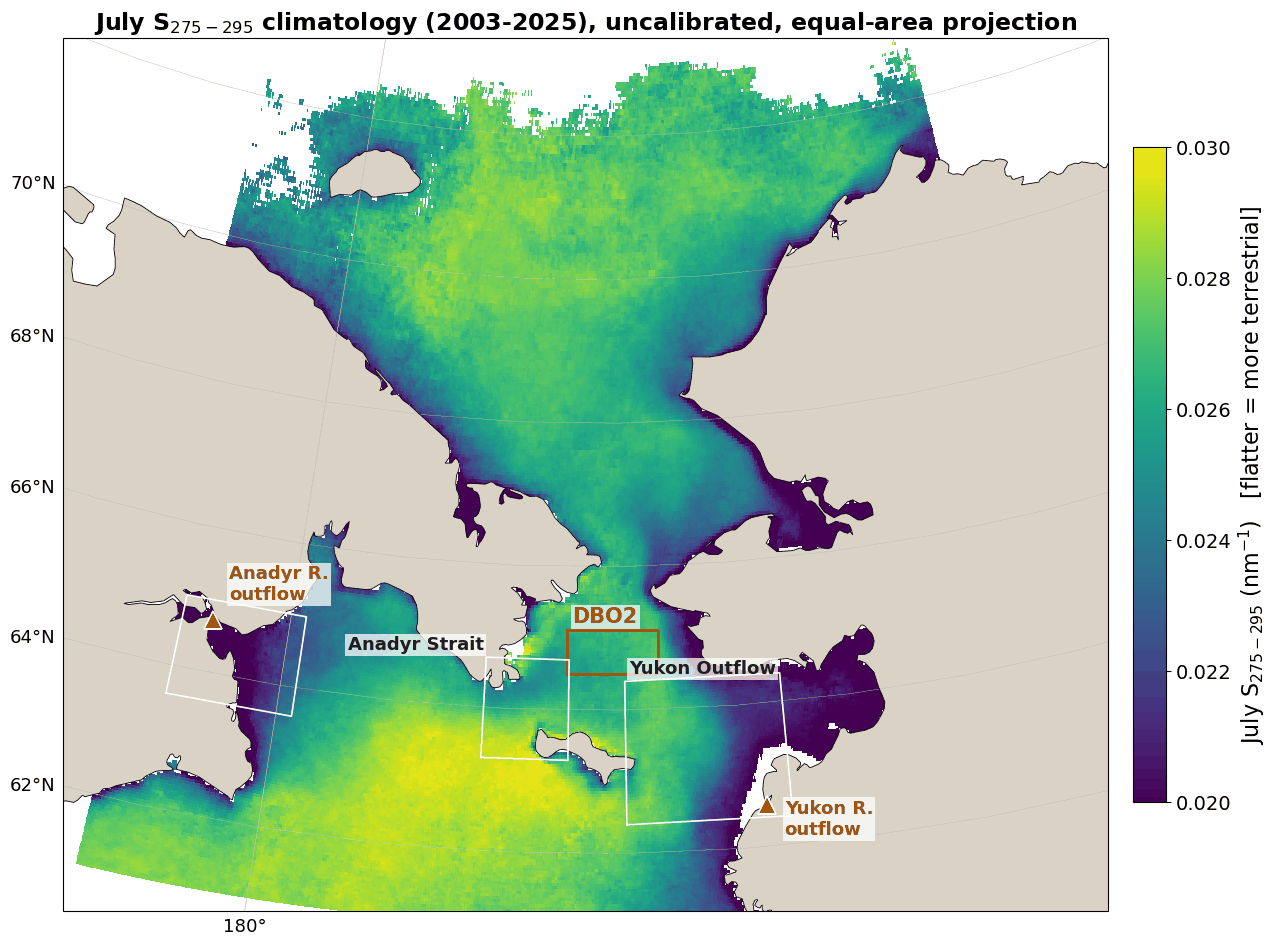

In [22]:
# FONT SCALE (raised 2026-08-28) — title, colorbar, gridline labels, map annotations.
FS_TITLE, FS_CB, FS_CBT, FS_GRID, FS_LBL = 17, 16, 14, 13, 13

# §9 — equal-area projected map, UNCALIBRATED July climatology + river-source markers
# Runs after §7 (needs sum_map/cnt_map, LONg/LATg, RING8). All values are genuine algorithm
# outputs inside the validated range; contrasts read as conservative lower bounds.
import cartopy.crs as ccrs
import cartopy.feature as cfeature

clim_raw = np.where(cnt_map >= 20, sum_map / np.maximum(cnt_map, 1), np.nan)

proj = ccrs.LambertAzimuthalEqualArea(central_longitude=-170, central_latitude=66)
pc = ccrs.PlateCarree()

DRAW_BOXES = {                       # (lat0, lat1, lon0, lon1), canonical
    'Anadyr Inner':  (63.6, 65.0, -183.5, -179.5),   # 176.5E-180.5E
    'Anadyr Strait': (63.3, 64.7, -173.5, -170.8),   # 186.5-189.2 lon360
    'Yukon Outflow':         (62.4, 64.4, -169.0, -164.0),   # Yukon-side feed (Chirikov)
}
LBL = dict(fontsize=FS_LBL, color='#1a1a1a', fontweight='bold', zorder=5,
           bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.5))
# per-box label placement; anything not listed goes at the box's top-left corner, left-aligned.
# 'Anadyr Strait' is right-aligned and nudged west so it clears the DBO2 label.
LBL_POS = {   # name -> (lon, lat, ha)
    'Anadyr Strait': (-173.60, 64.80, 'right'),
}
SKIP_LBL = {'Anadyr Inner'}   # box still drawn, label omitted (crowds the Anadyr R. marker)

fig = plt.figure(figsize=(13.5, 9.5))
ax = plt.axes(projection=proj)
ax.set_extent([-185.5, -155, 61.2, 72.8], crs=pc)
pm = ax.pcolormesh(LONg, LATg, clim_raw, cmap='viridis', vmin=0.020, vmax=0.030,
                   shading='auto', transform=pc)
ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#d9d2c5', zorder=2)
ax.coastlines('50m', lw=0.6, zorder=3)
cb = plt.colorbar(pm, ax=ax, shrink=0.75, pad=0.02)
cb.set_label('July S$_{275-295}$ (nm$^{-1}$)   [flatter = more terrestrial]', fontsize=FS_CB)
cb.ax.tick_params(labelsize=FS_CBT)

rr = RING8 + [RING8[0]]                              # DBO2 polygon (canonical box)
ax.plot([q[1] for q in rr], [q[0] for q in rr], '-', color='#D55E00', lw=2,
        transform=pc, zorder=4)
ax.text(-170.7, 65.22, 'DBO2', color='#D55E00', fontweight='bold', fontsize=FS_LBL + 2,
        transform=pc, zorder=5,
        bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.5))

for name, (a0, a1, o0, o1) in DRAW_BOXES.items():
    ax.plot([o0, o1, o1, o0, o0], [a0, a0, a1, a1, a0], '-', color='white',
            lw=1.2, transform=pc, zorder=4)
    if name in SKIP_LBL:
        continue
    tlo, tla, tha = LBL_POS.get(name, (o0 + 0.15, a1 + 0.10, 'left'))
    ax.text(tlo, tla, name, transform=pc, ha=tha, **LBL)

# river outflows
ax.plot(-164.75, 62.58, marker='^', ms=13, color='#8a4b0f', mec='white', mew=1.2,
        transform=pc, zorder=6)
ax.text(-164.3, 62.15, 'Yukon R.\noutflow', fontsize=FS_LBL, color='#8a4b0f',
        fontweight='bold', transform=pc, zorder=6,
        bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.5))
ax.plot(-182.49, 64.73, marker='^', ms=13, color='#8a4b0f', mec='white', mew=1.2,
        transform=pc, zorder=6)
ax.text(-182.1, 65.05, 'Anadyr R.\noutflow', fontsize=FS_LBL, color='#8a4b0f',
        fontweight='bold', ha='left', transform=pc, zorder=6,
        bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.5))

gl = ax.gridlines(draw_labels=True, lw=0.3, color='#bbbbbb')
gl.top_labels = gl.right_labels = False
gl.xlabel_style = {'size': FS_GRID}; gl.ylabel_style = {'size': FS_GRID}
ax.set_title('July S$_{275-295}$ climatology (2003-2025), uncalibrated, equal-area projection',
             fontsize=FS_TITLE, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_map_projected_uncalibrated.png', dpi=300, bbox_inches='tight')
plt.show()




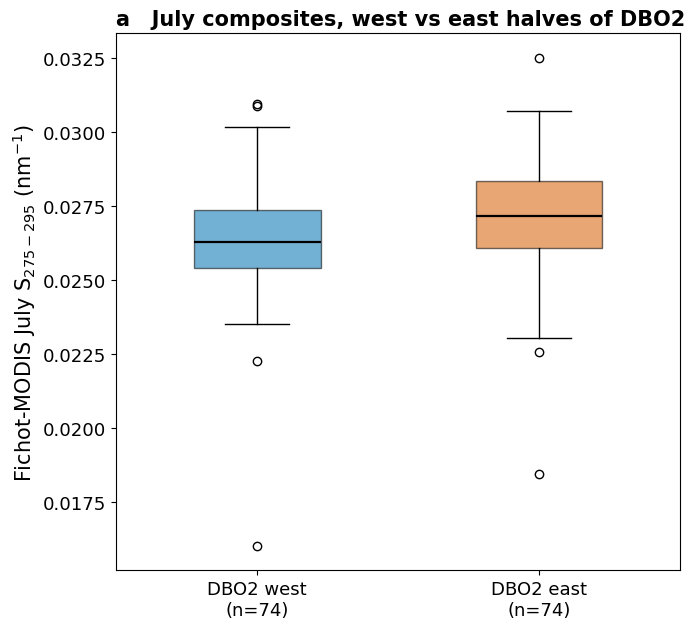

n paired July composites      74
median west - east            -0.9e-3 nm^-1
composites with west flatter  74%
paired Wilcoxon               p = 1.82e-05
July-mean trends per side:
  west: -0.06e-3/yr (p = 0.054)
  east: -0.12e-3/yr (p = 0.047)
difference trend              -0.00e-3/yr (p = 1.00)  -> gap constant; both sides decline together


In [21]:
# FONT SCALE (raised 2026-08-28) — panel titles, axis labels, ticks.
FS_PANEL, FS_AXL, FS_TICK = 15, 15, 13

# §10b — west-east offset, boxplot only (instant: reads SPLIT_CACHE, no streaming)
# Panel b (the 74 paired differences) is no longer drawn, but every statistic it carried is
# still computed and printed below, so the caption numbers stay available.
from scipy.stats import wilcoxon

rows10 = pickle.load(open(OUTDIR / 'fichot_dbo2_split_trend.pkl', 'rb'))
T10 = pd.DataFrame(rows10)
both = T10.dropna(subset=['west', 'east']).copy()
both['diff'] = both.west - both.east
w = wilcoxon(both['diff'])
trend_txt = []
for s in ['west', 'east']:
    ann = both.groupby('year')[s].mean()
    ts = theilslopes(ann.values, ann.index.values)
    kt = kendalltau(ann.index, ann.values)
    trend_txt.append(f'  {s}: {ts[0]*1000:+.2f}e-3/yr (p = {kt.pvalue:.3f})')
annd = both.groupby('year')['diff'].mean()
tsd = theilslopes(annd.values, annd.index.values)
ktd = kendalltau(annd.index, annd.values)

fig, ax = plt.subplots(figsize=(7.0, 6.4))
bp = ax.boxplot([both.west, both.east], positions=[1, 2], widths=0.45, patch_artist=True,
                tick_labels=[f'DBO2 west\n(n={len(both)})', f'DBO2 east\n(n={len(both)})'],
                medianprops=dict(color='black', lw=1.6))
for patch, c in zip(bp['boxes'], ['#0072B2', '#D55E00']):
    patch.set_facecolor(c); patch.set_alpha(0.55)
ax.set_ylabel('Fichot-MODIS July S$_{275-295}$ (nm$^{-1}$)', fontsize=FS_AXL)
ax.set_title('a   July composites, west vs east halves of DBO2',
             fontsize=FS_PANEL, loc='left', fontweight='bold')
ax.tick_params(labelsize=FS_TICK)
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_dbo2_split_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- numbers for the caption (previously the panel-b annotation) -----------------------
print(f'n paired July composites      {len(both)}')
print(f'median west - east            {both["diff"].median()*1000:+.1f}e-3 nm^-1')
print(f'composites with west flatter  {(both["diff"] < 0).mean():.0%}')
print(f'paired Wilcoxon               p = {w.pvalue:.3g}')
print('July-mean trends per side:'); print('\n'.join(trend_txt))
print(f'difference trend              {tsd[0]*1000:+.2f}e-3/yr (p = {ktd.pvalue:.2f})'
      '  -> gap constant; both sides decline together')


## 8 · East vs west DBO 2 through time — streams the split cache, then the boxplot (Fig. 9b)

In [16]:
# §10 — Fichot-MODIS east vs west DBO2 through time (the satellite version of the flank test)
# Canonical box lat bounds, split at lon -169.36 (same line as the bottle and PACE splits).
# Paired west-east offset = the powered test (common-mode cancels); per-side trends expected
# noisy (known interannual blindness); difference trend ~0 would AGREE with the in-situ
# finding that the flattening is on both flanks equally.
from scipy.stats import wilcoxon

SPLIT_CACHE = OUTDIR / 'fichot_dbo2_split_trend.pkl'
LATb0, LATb1 = 64.481828, 65.107747
LONw0, LONmid, LONe1 = -170.865176, -169.36, -167.859549

if SPLIT_CACHE.exists():
    rows10 = pickle.load(open(SPLIT_CACHE, 'rb'))
else:
    rows10 = []
    for yr in range(2003, 2026):
        store10 = modis_8day_rrs(pd.Timestamp(f'{yr}-06-26'), pd.Timestamp(f'{yr}-08-05'))
        for per in sorted({k[0] for k in store10}):
            if per.month != 7: continue
            if not all((per, b) in store10 for b in BANDS): continue
            das = {b: store10[(per, b)] for b in BANDS}
            LON2, LAT2 = np.meshgrid(das[443].lon.values, das[443].lat.values)
            arr = {b: das[b].values for b in BANDS}
            valid = np.all([np.isfinite(arr[b]) & (arr[b] > 0) for b in BANDS], axis=0)
            inlat = (LAT2 >= LATb0) & (LAT2 <= LATb1)
            row = dict(year=yr, period=per)
            for name, m in [('west', inlat & (LON2 >= LONw0) & (LON2 < LONmid)),
                            ('east', inlat & (LON2 >= LONmid) & (LON2 <= LONe1))]:
                mm = valid & m
                if mm.sum() >= 20:
                    s = fichot_s275({b: arr[b][mm] for b in BANDS})
                    row[name] = float(np.median(s))
            if ('west' in row) or ('east' in row):
                rows10.append(row)
        pickle.dump(rows10, open(SPLIT_CACHE, 'wb'))
        print(yr, len(rows10), 'composites')

T10 = pd.DataFrame(rows10)
both = T10.dropna(subset=['west', 'east']).copy()
both['diff'] = both.west - both.east
w = wilcoxon(both['diff'])
print(f"\npaired west-east (n={len(both)} July composites): median {both['diff'].median():+.4f}, "
      f"{(both['diff'] < 0).mean():.0%} of composites west flatter, Wilcoxon p={w.pvalue:.4f}")
for s in ['west', 'east']:
    ann = both.groupby('year')[s].mean()
    ts = theilslopes(ann.values, ann.index.values)
    kt = kendalltau(ann.index, ann.values)
    print(f'{s} July-mean trend: {ts[0]*1000:+.3f}e-3/yr '
          f'(CI {ts[2]*1000:+.3f}..{ts[3]*1000:+.3f})  p={kt.pvalue:.3f}')
annd = both.groupby('year')['diff'].mean()
tsd = theilslopes(annd.values, annd.index.values)
ktd = kendalltau(annd.index, annd.values)
print(f'west-east difference trend: {tsd[0]*1000:+.3f}e-3/yr  p={ktd.pvalue:.3f}')

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for s, colr in [('west', '#0072B2'), ('east', '#D55E00')]:
    ax.plot(both.year + (both.period.dt.dayofyear - 182)/120, both[s], 'o', ms=3,
            color=colr, alpha=0.3)
    ann = both.groupby('year')[s].mean()
    ax.plot(ann.index, ann.values, 'o-', ms=6, color=colr, lw=1.4,
            label=f'DBO2 {s} (July mean)')
ax.set_ylabel('Fichot-MODIS S$_{275-295}$ (nm$^{-1}$)')
ax.legend(fontsize=8); ax.grid(alpha=0.25)
ax.set_title('a   Fichot-MODIS July S$_{275-295}$ by DBO2 side, 2003–2025',
             fontsize=10, loc='left')
ax2.axhline(0, color='#888888', lw=0.9)
ax2.plot(both.year + (both.period.dt.dayofyear - 182)/120, both['diff']*1000, 'o',
         ms=4, color='#6A51A3', alpha=0.5)
ax2.plot(annd.index, annd.values*1000, 'o-', ms=6, color='black', lw=1.2,
         label='July mean')
xx = np.array([2003, 2025])
ax2.plot(xx, (tsd[1] + tsd[0]*xx)*1000, '-' if ktd.pvalue < 0.05 else '--',
         color='#6A51A3', lw=2)
ax2.set_ylabel('west $-$ east ($\\times$10$^{-3}$ nm$^{-1}$)')
ax2.set_title(f'b   paired west$-$east: median {both["diff"].median()*1000:+.1f}'
              f'$\\times$10$^{{-3}}$ (Wilcoxon p = {w.pvalue:.3f}) | '
              f'difference trend {tsd[0]*1000:+.2f}$\\times$10$^{{-3}}$/yr (p = {ktd.pvalue:.2f})',
              fontsize=10, loc='left')
ax2.set_xlabel('year'); ax2.grid(alpha=0.25); ax2.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTDIR / 'fichot_dbo2_split_trend.png', dpi=300, bbox_inches='tight')
plt.show()



paired west-east (n=74 July composites): median -0.0009, 74% of composites west flatter, Wilcoxon p=0.0000
west July-mean trend: -0.062e-3/yr (CI -0.163..+0.005)  p=0.054
east July-mean trend: -0.116e-3/yr (CI -0.210..-0.002)  p=0.047
west-east difference trend: -0.000e-3/yr  p=1.000
